In [1]:
# 806     202     248
import numpy as np
import mrcfile
import torch
from torch_transform_image import affine_transform_image_3d
from torch_affine_utils.transforms_3d import Rx,Ry,Rz, T, S  # Rotation, Translation, Scale
import matplotlib.pyplot as plt

In [2]:
Best_BP = "/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/15F1_tomograms/TOP_TOMOS/20240523_HippWaffle_168/best_alignment/20240523_HippWaffle_168_full_rec_BP_3DCTF_BIN4.mrc"
Best_DDW = "/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/15F1_tomograms/TOP_TOMOS/20240523_HippWaffle_168/best_alignment/20240523_HippWaffle_168_full_rec_BP_3DCTF_BIN4_ddw.mrc"

GOLD_BP = "/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/15F1_tomograms/TOP_TOMOS/20240523_HippWaffle_168/gold_alignment/20240523_HippWaffle_168_full_rec_BP_3DCTF_BIN4.mrc"
GOLD_DDW = "/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/15F1_tomograms/TOP_TOMOS/20240523_HippWaffle_168/gold_alignment/20240523_HippWaffle_168_full_rec_BP_3DCTF_BIN4_ddw.mrc"


In [3]:
az_data = np.load("/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/15F1_tomograms/TOP_TOMOS/20240523_HippWaffle_168/best_alignment/active_zonograms/active_zonogram_0.npy",allow_pickle=True)

In [4]:
az_data.item()["center"]

array([553.33823868, 375.67628314, 257.20349215])

In [34]:
ex_ddw = "/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/15F1_tomograms/TOP_TOMOS/20240523_HippWaffle_168/best_alignment/active_zonograms/active_zonogram_0.mrc"
with mrcfile.open(ex_ddw) as mrc:
        ex_ddw_data = torch.tensor(mrc.data.copy())

In [5]:
with mrcfile.open(Best_BP) as mrc:
        tomogram_data_ddw = torch.tensor(mrc.data.copy())

In [25]:
to_center = T(-az_data.item()["center"][::-1])

In [48]:
cs = Rx(0) 
cs[0,:3,:3] = torch.tensor(az_data.item()["cs"])
cs

tensor([[[-0.8672, -0.4980,  0.0000,  0.0000],
         [-0.0519,  0.0904, -0.9945,  0.0000],
         [ 0.4953, -0.8624, -0.1043,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  1.0000]]])

In [27]:
extend=[248,202,806]

In [28]:
back_to_origin = T(torch.tensor(extend)/2)

In [47]:
cs[0] = cs[0].clone().T
cs

tensor([[[-0.8672, -0.0519,  0.4953,  0.0000],
         [-0.4980,  0.0904, -0.8624,  0.0000],
         [ 0.0000, -0.9945, -0.1043,  0.0000],
         [ 0.0000,  0.0000,  0.0000,  1.0000]]])

In [49]:
transform = back_to_origin @ cs @ to_center
transform = torch.linalg.inv(transform)

In [50]:
result = affine_transform_image_3d(
    image=tomogram_data_ddw,
    matrices=transform, 
    interpolation='trilinear',  # Options: 'nearest', 'trilinear'
    zyx_matrices=True,  # The generated translations have [z, y, x] order
    output_shape=extend,
)

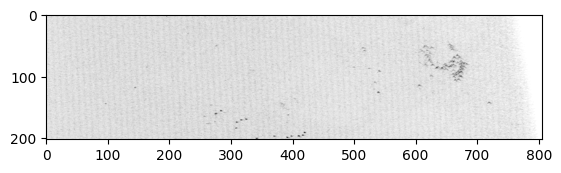

In [51]:
plt.imshow(torch.min(result, dim=0)[0].cpu().numpy(), cmap='gray')

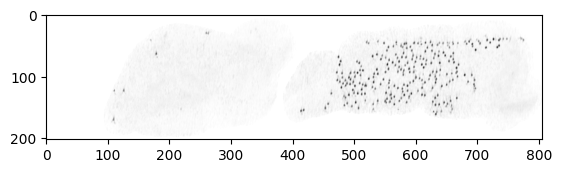

In [36]:
plt.imshow(torch.min(ex_ddw_data, dim=0)[0].cpu().numpy(), cmap='gray')

Starting grid sample


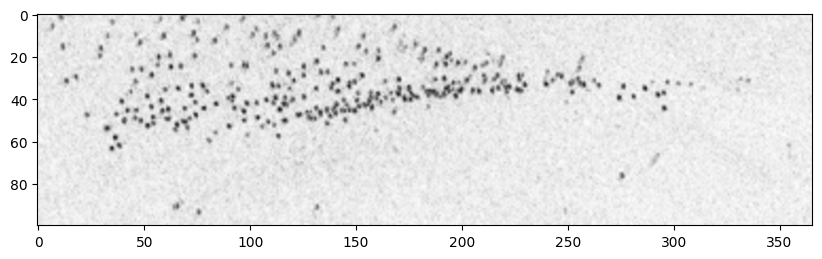

In [71]:
with mrcfile.open(Best_BP) as mrc:
    tomogram_data_ddw = torch.tensor(mrc.data.copy())
w = extend[2]
h = extend[1]
d = extend[0]
coordinate_system = az_data.item()["cs"]
ap_center = az_data.item()["center"]
x = torch.arange(0, w-0.99, 1, dtype=torch.float64) - w / 2
y = torch.arange(0, h-0.99, 1, dtype=torch.float64) - h / 2
z = torch.arange(0, d-0.99, 1, dtype=torch.float64) - d / 2 
mg = torch.cartesian_prod(x, y, z)
grid = mg @ torch.tensor(coordinate_system) + torch.tensor(ap_center)
if grid.shape[1] > 90000000:
    raise ValueError("Too many points to plot")



grid_sc = grid / (torch.tensor(tomogram_data_ddw.shape).flip(dims=(0,)).double() / 2.0 ) - 1.0


grid_sc = grid_sc.reshape(1,w,h,d,3).float()
tomogram_data_ddw_sc = tomogram_data_ddw.reshape(1,1, *tomogram_data_ddw.shape)
print("Starting grid sample")
res_ddw = torch.nn.functional.grid_sample(tomogram_data_ddw_sc, grid_sc,align_corners=True)

res_ddw = res_ddw [0,0]
rshape = res_ddw.shape
res_ddw = res_ddw.permute(*torch.arange(res_ddw.ndim - 1, -1, -1))
plt.figure(figsize=(10, 10))
plt.imshow(torch.min(res_ddw, dim=1)[0].cpu().numpy()[0:100,440:], cmap='gray',interpolation='mitchell')

Starting grid sample


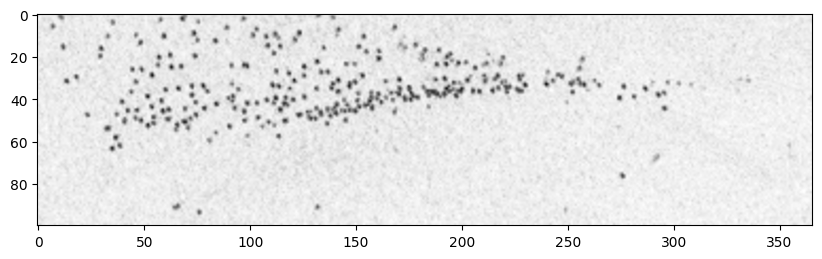

In [70]:
with mrcfile.open(GOLD_BP) as mrc:
    tomogram_data_ddw = torch.tensor(mrc.data.copy())
w = extend[2]
h = extend[1]
d = extend[0]
coordinate_system = az_data.item()["cs"]
ap_center = az_data.item()["center"]
x = torch.arange(0, w-0.99, 1, dtype=torch.float64) - w / 2
y = torch.arange(0, h-0.99, 1, dtype=torch.float64) - h / 2
z = torch.arange(0, d-0.99, 1, dtype=torch.float64) - d / 2 
mg = torch.cartesian_prod(x, y, z)
grid = mg @ torch.tensor(coordinate_system) + torch.tensor(ap_center)
if grid.shape[1] > 90000000:
    raise ValueError("Too many points to plot")



grid_sc = grid / (torch.tensor(tomogram_data_ddw.shape).flip(dims=(0,)).double() / 2.0 ) - 1.0


grid_sc = grid_sc.reshape(1,w,h,d,3).float()
tomogram_data_ddw_sc = tomogram_data_ddw.reshape(1,1, *tomogram_data_ddw.shape)
print("Starting grid sample")
res_ddw = torch.nn.functional.grid_sample(tomogram_data_ddw_sc, grid_sc,align_corners=True)

res_ddw = res_ddw [0,0]
rshape = res_ddw.shape
res_ddw = res_ddw.permute(*torch.arange(res_ddw.ndim - 1, -1, -1))
plt.figure(figsize=(10, 10))
plt.imshow(torch.min(res_ddw, dim=1)[0].cpu().numpy()[0:100,440:], cmap='gray',interpolation='mitchell')

Starting grid sample


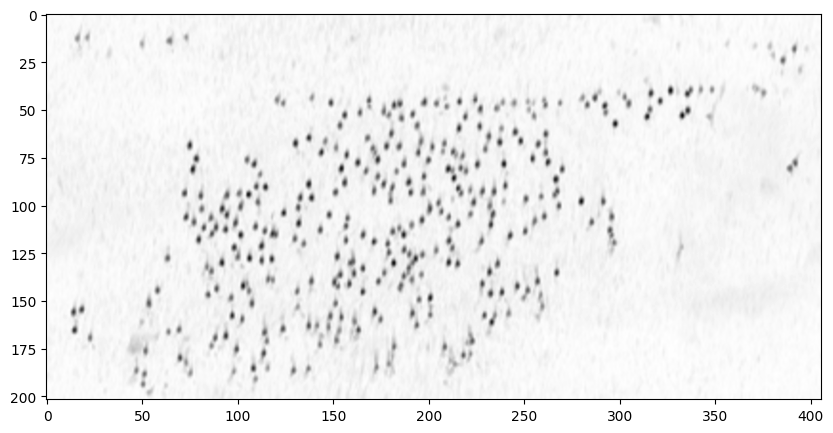

In [61]:
with mrcfile.open(Best_DDW) as mrc:
    tomogram_data_ddw = torch.tensor(mrc.data.copy())
w = extend[2]
h = extend[1]
d = extend[0]
coordinate_system = az_data.item()["cs"]
ap_center = az_data.item()["center"]
x = torch.arange(0, w-0.99, 1, dtype=torch.float64) - w / 2
y = torch.arange(0, h-0.99, 1, dtype=torch.float64) - h / 2
z = torch.arange(0, d-0.99, 1, dtype=torch.float64) - d / 2 
mg = torch.cartesian_prod(x, y, z)
grid = mg @ torch.tensor(coordinate_system) + torch.tensor(ap_center)
if grid.shape[1] > 90000000:
    raise ValueError("Too many points to plot")



grid_sc = grid / (torch.tensor(tomogram_data_ddw.shape).flip(dims=(0,)).double() / 2.0 ) - 1.0


grid_sc = grid_sc.reshape(1,w,h,d,3).float()
tomogram_data_ddw_sc = tomogram_data_ddw.reshape(1,1, *tomogram_data_ddw.shape)
print("Starting grid sample")
res_ddw = torch.nn.functional.grid_sample(tomogram_data_ddw_sc, grid_sc,align_corners=True)

res_ddw = res_ddw [0,0]
rshape = res_ddw.shape
res_ddw = res_ddw.permute(*torch.arange(res_ddw.ndim - 1, -1, -1))
plt.figure(figsize=(10, 10))
plt.imshow(torch.min(res_ddw, dim=0)[0].cpu().numpy()[:,400:], cmap='gray',interpolation='mitchell')

Starting grid sample


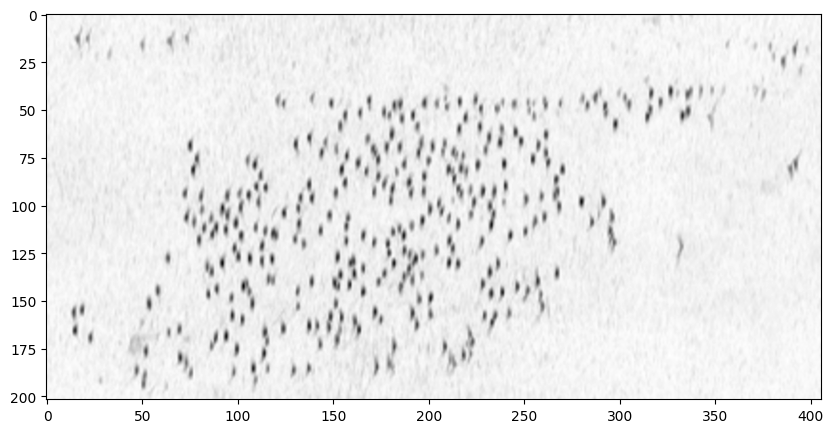

In [62]:
with mrcfile.open(GOLD_DDW) as mrc:
    tomogram_data_ddw = torch.tensor(mrc.data.copy())
w = extend[2]
h = extend[1]
d = extend[0]
coordinate_system = az_data.item()["cs"]
ap_center = az_data.item()["center"]
x = torch.arange(0, w-0.99, 1, dtype=torch.float64) - w / 2
y = torch.arange(0, h-0.99, 1, dtype=torch.float64) - h / 2
z = torch.arange(0, d-0.99, 1, dtype=torch.float64) - d / 2 
mg = torch.cartesian_prod(x, y, z)
grid = mg @ torch.tensor(coordinate_system) + torch.tensor(ap_center)
if grid.shape[1] > 90000000:
    raise ValueError("Too many points to plot")



grid_sc = grid / (torch.tensor(tomogram_data_ddw.shape).flip(dims=(0,)).double() / 2.0 ) - 1.0


grid_sc = grid_sc.reshape(1,w,h,d,3).float()
tomogram_data_ddw_sc = tomogram_data_ddw.reshape(1,1, *tomogram_data_ddw.shape)
print("Starting grid sample")
res_ddw = torch.nn.functional.grid_sample(tomogram_data_ddw_sc, grid_sc,align_corners=True)

res_ddw = res_ddw [0,0]
rshape = res_ddw.shape
res_ddw = res_ddw.permute(*torch.arange(res_ddw.ndim - 1, -1, -1))
plt.figure(figsize=(10, 10))
plt.imshow(torch.min(res_ddw, dim=0)[0].cpu().numpy()[:,400:], cmap='gray',interpolation='mitchell')